Mounted at /content/drive
Dataset extracted to /content/dataset
Device: cuda
Detected 2 classes: ['benign', 'malignant']
Train samples: 2637 Val samples: 660
Samples per class: [1440, 1197]


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Using model: vit_large_patch16_224
Trainable head params groups: 2
Starting Phase 1 (head-only)


/tmp/ipython-input-3744007642.py:261: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
Train 1/60:   0%|                                                                                | 0/83 [00:00<?, ?it/s]/tmp/ipython-input-3744007642.py:314: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/usr/local/lib/python3.12/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/doc

Epoch 1/12 summary: train_acc=0.4573 val_acc=0.5364 val_loss=0.7780 val_auc=0.5605 time=102.9s
Saved best (phase1) to: /content/drive/MyDrive/best_vit_highpower.pt


... (86 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Train 45/60:   0%|                                                                               | 0/83 [00:00<?, ?it/s]/tmp/ipython-input-3744007642.py:314: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Val 45:   0%|                                                                                    | 0/21 [00:00<?, ?it/s]/tmp/ipython-input-3744007642.py:380: FutureWarning: `torch.cuda.amp.autocast

Epoch 45/60 summary: train_acc=0.7914 val_acc=0.9015 val_loss=0.3426 val_auc=0.9562 time=113.7s
No improvement: 12/12
Early stopping triggered in Phase 2.
Applying SWA finalization and bn update.
Loading best saved state (best checkpoint) into model for final eval.


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Val final:   0%|                                                                                 | 0/21 [00:00<?, ?it/s]/tmp/ipython-input-3744007642.py:380: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Val final:   5%|▏   | 1/21 [00:03<01:15,  3.75s/it, b_loss=0.2910, b_acc=0.875, e_loss=0.2910, e_acc=0.8750, GPU=6.99GB]/tmp/ipython-input-3744007642.py:380: FutureWarning: `torch.cuda.amp.autocast


Final Validation Accuracy: 90.45%

Classification Report:
               precision    recall  f1-score   support

      benign       0.90      0.93      0.91       360
   malignant       0.91      0.87      0.89       300

    accuracy                           0.90       660
   macro avg       0.91      0.90      0.90       660
weighted avg       0.90      0.90      0.90       660

Macro AUC: 0.9615462962962963
Saved final model to: /content/drive/MyDrive/final_vit_highpower.pt


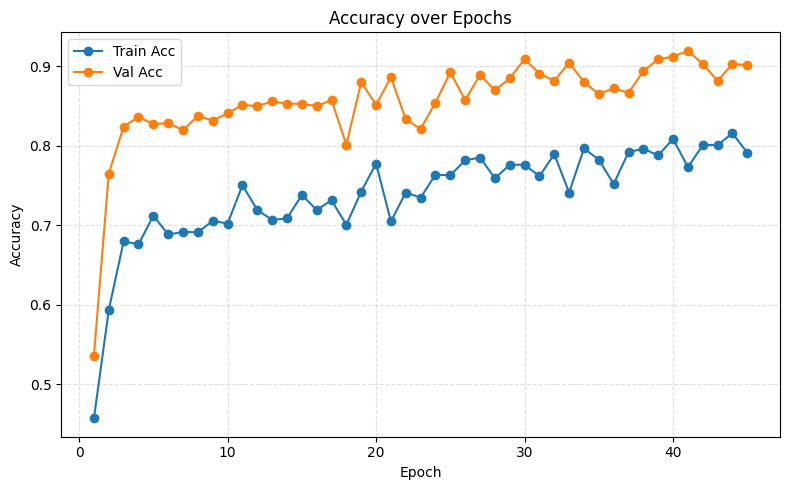

Saved accuracy plot to: /content/drive/MyDrive/diabetic_eye_results/highpower_accuracy.png


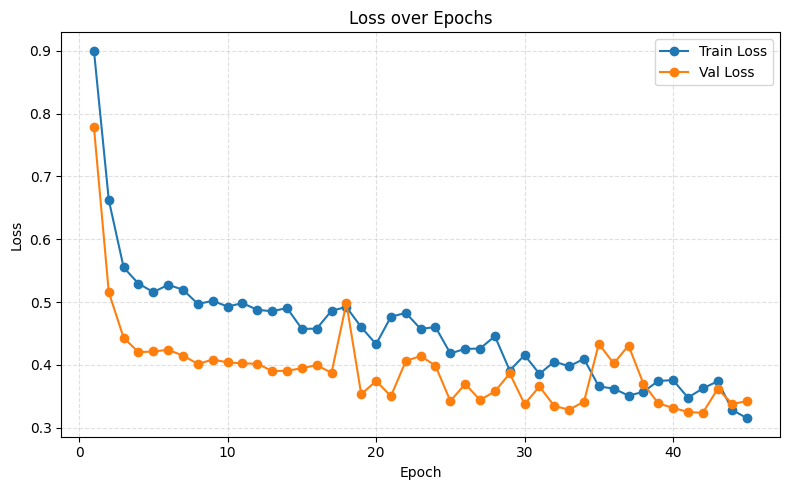

Saved loss plot to: /content/drive/MyDrive/diabetic_eye_results/highpower_loss.png


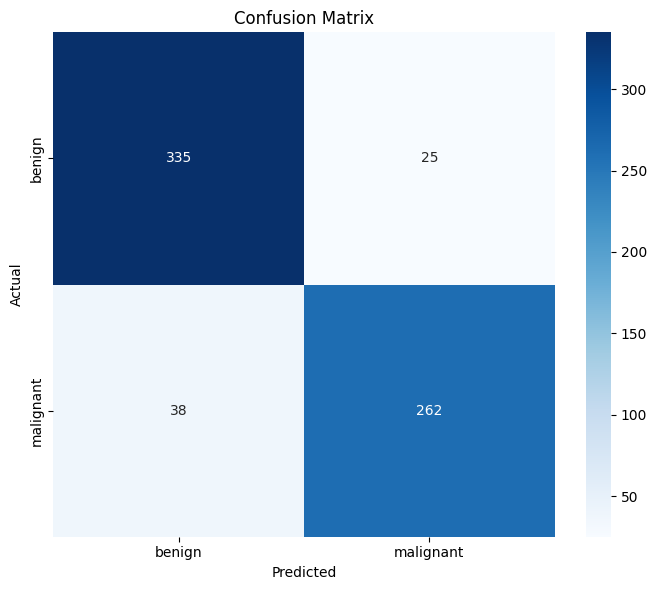

Saved confusion matrix to: /content/drive/MyDrive/diabetic_eye_results/highpower_confusion_matrix.png


In [1]:
# High-power ViT training script designed to maximize chance of >=95% train & val accuracy.
# Keep dataset paths unchanged.
# Requirements: torch, torchvision, timm, scikit-learn, tqdm, matplotlib, seaborn

import os
import random
import zipfile
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR
from torch.optim.swa_utils import AveragedModel, SWALR
from torchvision import transforms, datasets
import timm
from tqdm import tqdm

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data.sampler import WeightedRandomSampler

# ---------------- Configuration (edit carefully) ----------------
DRIVE_MOUNT = True
ZIP_PATH = "/content/drive/MyDrive/d.zip"            # dataset zip on Drive (if used)
EXTRACT_PATH = "/content/dataset"
TRAIN_DIR = "/content/dataset/d/train"
VAL_DIR   = "/content/dataset/d/val"
GRAPH_DIR = "/content/drive/MyDrive/diabetic_eye_results"
CHECKPOINT_PATH = "/content/drive/MyDrive/best_vit_highpower.pt"
FINAL_MODEL_PATH = "/content/drive/MyDrive/final_vit_highpower.pt"

# Choose model: for high chance of 95+ set to 'vit_large_patch16_224' if GPU RAM >= 16GB.
# If OOM, switch to 'vit_base_patch16_224' or 'efficientnet_b4'
MODEL_NAME = "vit_large_patch16_224"
FALLBACK_MODEL = "vit_base_patch16_224"  # used automatically on OOM
IMG_SIZE = 224

# Training params (aggressive)
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42
PHASE1_EPOCHS = 12        # head-only
PHASE2_EPOCHS = 48        # fine-tune
N_UNFREEZE = 12           # unfreeze last N transformer blocks (or entire model if needed)
SHOW_GPU_MEM = True

# High-performance hyperparams
HEAD_LR = 3e-4
FINETUNE_LR = 3e-5
WEIGHT_DECAY = 1e-2
MAX_GRAD_NORM = 1.0
LABEL_SMOOTHING = 0.05
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
CUTMIX_PROB = 0.5
SWA_START_EPOCH = PHASE1_EPOCHS + PHASE2_EPOCHS - 8  # start SWA in final 8 epochs
EARLY_STOPPING_PATIENCE = 12
ACCUMULATION_STEPS = 1

# TTA during validation (list of transforms to apply and average)
TTA_TRANSFORMS = [
    lambda x: x,  # identity
    lambda x: torch.flip(x, dims=[-1]),  # horizontal
    lambda x: torch.flip(x, dims=[-2]),  # vertical
]

# ---------------- Reproducibility ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

# ---------------- Mount Drive & extract dataset (Colab) ----------------
if DRIVE_MOUNT:
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception:
        pass

if os.path.exists(ZIP_PATH) and not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
        print("Dataset extracted to", EXTRACT_PATH)
else:
    print("Zip not found or dataset already extracted (or already extracted).")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)

# ---------------- Device & checks ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if not os.path.isdir(TRAIN_DIR) or not os.path.isdir(VAL_DIR):
    raise FileNotFoundError(f"Train/Val directories not found. Expected: {TRAIN_DIR} and {VAL_DIR}")

# ---------------- Class discovery ----------------
classes = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
num_classes = len(classes)
print(f"Detected {num_classes} classes: {classes}")

# ---------------- Transforms (RandAugment, Cutout via RandomErasing) ----------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# Use RandAugment if available in torchvision, else skip gracefully
randaugment = None
try:
    randaugment = transforms.RandAugment(num_ops=2, magnitude=9)
except Exception:
    randaugment = None

train_transform_list = [
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(30),
]
if randaugment is not None:
    train_transform_list.append(randaugment)

train_transform_list += [
    transforms.ColorJitter(brightness=0.2, contrast=0.15, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.01, 0.12)),
]
train_transform = transforms.Compose(train_transform_list)

val_transform = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# ---------------- Datasets ----------------
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset   = datasets.ImageFolder(VAL_DIR, transform=val_transform)
print("Train samples:", len(train_dataset), "Val samples:", len(val_dataset))

# ---------------- Weighted sampler to reduce class imbalance ----------------
y_train = [label for _, label in train_dataset.samples]
class_sample_count = np.array([len([1 for y in y_train if y == i]) for i in range(num_classes)])
print("Samples per class:", class_sample_count.tolist())

if len(y_train) > 0 and num_classes > 1:
    class_weights_np = compute_class_weight(class_weight='balanced', classes=np.arange(num_classes), y=y_train)
    class_weights = torch.tensor(class_weights_np, dtype=torch.float).to(device)
    # WeightedRandomSampler
    sample_weights = np.array([class_weights_np[y] for y in y_train], dtype=np.float32)
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
else:
    class_weights = None
    sampler = None

# DataLoaders (use sampler for train if imbalance)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE,
                                           sampler=sampler if sampler is not None else None,
                                           shuffle=(sampler is None),
                                           num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                           num_workers=NUM_WORKERS, pin_memory=True)

# ---------------- Model creation with fallback on OOM ----------------
def create_model_or_fallback(name):
    try:
        m = timm.create_model(name, pretrained=True, num_classes=num_classes)
        return m, name
    except RuntimeError as e:
        print(f"OOM or error creating {name}: {e}")
        if name != FALLBACK_MODEL:
            print(f"Falling back to {FALLBACK_MODEL}")
            m = timm.create_model(FALLBACK_MODEL, pretrained=True, num_classes=num_classes)
            return m, FALLBACK_MODEL
        else:
            raise

model, used_model_name = create_model_or_fallback(MODEL_NAME)
model.to(device)
print("Using model:", used_model_name)

# ---------------- Head freeze then unfreeze strategy ----------------
for n, p in model.named_parameters():
    p.requires_grad = False

# Attempt to unfreeze classifier head
head_param_count = 0
for name, p in model.named_parameters():
    if ("head" in name) or ("classifier" in name) or name.endswith("fc") or "norm" in name and "head" in name:
        p.requires_grad = True
        head_param_count += 1
if head_param_count == 0:
    # fallback unfreeze last linear
    for name, p in model.named_parameters():
        if name.endswith(('head', 'classifier', 'fc', 'proj', 'out_proj')):
            p.requires_grad = True
            head_param_count += 1
print("Trainable head params groups:", head_param_count)

# ---------------- Loss, MixUp, CutMix ----------------
def get_criterion():
    try:
        return nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
    except TypeError:
        return nn.CrossEntropyLoss(weight=class_weights)

criterion = get_criterion()

def mixup_data(x, y, alpha=MIXUP_ALPHA):
    if alpha <= 0:
        return x, y, None, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    if batch_size == 1:
        return x, y, None, 1.0
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=CUTMIX_ALPHA):
    # returns mixed images and pairs
    if alpha <= 0:
        return x, y, None, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size, c, h, w = x.size()
    index = torch.randperm(batch_size).to(x.device)
    # compute cutout bbox
    cut_rat = np.sqrt(1. - lam)
    cut_w = int(w * cut_rat)
    cut_h = int(h * cut_rat)
    # center
    cx = np.random.randint(w)
    cy = np.random.randint(h)
    x1 = np.clip(cx - cut_w // 2, 0, w)
    y1 = np.clip(cy - cut_h // 2, 0, h)
    x2 = np.clip(cx + cut_w // 2, 0, w)
    y2 = np.clip(cy + cut_h // 2, 0, h)
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    # adjust lambda based on area
    lam_adj = 1. - ((x2 - x1) * (y2 - y1) / (w * h))
    y_a, y_b = y, y[index]
    return x, y_a, y_b, lam_adj

def mixup_criterion(pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

# ---------------- Utilities ----------------
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

def human_gpu_mem():
    if not torch.cuda.is_available() or not SHOW_GPU_MEM:
        return ""
    return f"{torch.cuda.memory_reserved(device)/1024**3:.2f}GB"

def compute_metrics_all(y_true_list, y_pred_list, y_prob_array, class_names):
    y_true = np.array(y_true_list)
    y_pred = np.array(y_pred_list)
    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
    if y_true_bin.ndim == 1:
        y_true_bin = y_true_bin.reshape(-1, 1)
    if y_true_bin.shape[1] == 1:
        y_true_bin = np.hstack([1 - y_true_bin, y_true_bin])
    fpr, tpr, roc_auc = {}, {}, {}
    aucs = []
    missing = []
    for i in range(n_classes):
        if np.sum(y_true_bin[:, i]) == 0:
            missing.append(class_names[i])
            continue
        try:
            fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob_array[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            aucs.append(roc_auc[i])
        except Exception:
            missing.append(class_names[i])
    macro_auc = np.mean(aucs) if len(aucs) > 0 else 0.0
    return acc, report, roc_auc, fpr, tpr, macro_auc, missing

# ---------------- Train/Validate (supports MixUp / CutMix & TTA) ----------------
def train_one_epoch(model, loader, optimizer, epoch, total_epochs, scheduler=None):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    pbar = tqdm(enumerate(loader, start=1), total=len(loader),
                desc=f"Train {epoch}/{total_epochs}", ncols=120, leave=False)
    for batch_idx, (imgs, labels) in pbar:
        imgs = imgs.to(device)
        labels = labels.to(device)

        # Randomly apply MixUp or CutMix
        use_cutmix = (np.random.rand() < CUTMIX_PROB)
        if use_cutmix:
            imgs_mixed, y_a, y_b, lam = cutmix_data(imgs.clone(), labels, alpha=CUTMIX_ALPHA)
        else:
            imgs_mixed, y_a, y_b, lam = mixup_data(imgs, labels, alpha=MIXUP_ALPHA)

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = model(imgs_mixed)
            if y_b is None:
                loss = criterion(logits, labels)
            else:
                loss = mixup_criterion(logits, y_a, y_b, lam)
            loss = loss / ACCUMULATION_STEPS

        scaler.scale(loss).backward()
        if MAX_GRAD_NORM is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)

        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad()
        if scheduler is not None and isinstance(scheduler, OneCycleLR):
            scheduler.step()

        running_loss += loss.item() * imgs.size(0) * ACCUMULATION_STEPS
        preds = logits.detach().argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
        running_epoch_loss = running_loss / total if total>0 else running_loss
        running_epoch_acc = correct / total if total>0 else 0.0

        postfix = {"b_loss": f"{loss.item()*ACCUMULATION_STEPS:.4f}",
                   "e_loss": f"{running_epoch_loss:.4f}",
                   "e_acc": f"{running_epoch_acc:.4f}"}
        if torch.cuda.is_available() and SHOW_GPU_MEM:
            postfix["GPU"] = human_gpu_mem()
        pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    avg_loss = running_loss / len(loader.dataset) if len(loader.dataset)>0 else 0.0
    return avg_loss, correct / total if total>0 else 0.0

def tta_predict_batch(model, imgs):
    # imgs: tensor batch; apply TTA transforms list and average softmax probs
    model.eval()
    probs_sum = None
    with torch.no_grad():
        for tfn in TTA_TRANSFORMS:
            aug_imgs = tfn(imgs)
            logits = model(aug_imgs)
            probs = F.softmax(logits, dim=1).cpu().numpy()
            probs_sum = probs if probs_sum is None else probs_sum + probs
    probs_avg = probs_sum / len(TTA_TRANSFORMS)
    return probs_avg

def validate(model, loader, epoch=None):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []
    pbar = tqdm(enumerate(loader, start=1), total=len(loader),
                desc=f"Val {epoch}" if epoch else "Val", ncols=120, leave=False)
    with torch.no_grad():
        for batch_idx, (imgs, labels) in pbar:
            imgs = imgs.to(device)
            labels = labels.to(device)
            # TTA averaged prediction
            probs = tta_predict_batch(model, imgs)
            preds = np.argmax(probs, axis=1)
            logits = torch.from_numpy(probs).to(device)  # not used for loss (approx)
            # compute loss using original logits to keep consistent; so forward pass again
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits_full = model(imgs)  # single pass
                loss = criterion(logits_full, labels)
            running_loss += loss.item() * imgs.size(0)
            all_probs.append(probs)
            all_preds.extend(list(preds))
            all_labels.extend(list(labels.cpu().numpy()))
            batch_acc = (preds == labels.cpu().numpy()).mean()
            running_epoch_loss = running_loss / (len(all_labels) if len(all_labels)>0 else 1)
            running_epoch_acc = accuracy_score(all_labels, all_preds) if len(all_labels)>0 else 0.0
            postfix = {"b_loss": f"{loss.item():.4f}", "b_acc": f"{batch_acc:.3f}", "e_loss": f"{running_epoch_loss:.4f}", "e_acc": f"{running_epoch_acc:.4f}"}
            if torch.cuda.is_available() and SHOW_GPU_MEM:
                postfix["GPU"] = human_gpu_mem()
            pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    val_loss = running_loss / len(loader.dataset) if len(loader.dataset)>0 else 0.0
    all_probs = np.vstack(all_probs) if all_probs else np.zeros((0, num_classes))
    return val_loss, all_labels, all_preds, all_probs

# ---------------- Training loop with OneCycleLR + SWA ----------------
history = {"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[], "val_auc_macro":[]}
best_score = -float('inf')
total_epochs = PHASE1_EPOCHS + PHASE2_EPOCHS
stopping_counter = 0

# Phase 1: head-only
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
steps_per_epoch = max(1, len(train_loader))
scheduler = OneCycleLR(optimizer, max_lr=HEAD_LR, total_steps=PHASE1_EPOCHS * steps_per_epoch)

print("Starting Phase 1 (head-only)")
for epoch in range(1, PHASE1_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, epoch, total_epochs, scheduler=scheduler)
    val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, epoch)
    _, _, _, _, _, val_auc_macro, _ = compute_metrics_all(y_true_val, y_pred_val, y_prob_val, classes)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(accuracy_score(y_true_val, y_pred_val))
    history["val_auc_macro"].append(val_auc_macro)

    combined = -val_loss + val_auc_macro
    print(f"Epoch {epoch}/{PHASE1_EPOCHS} summary: train_acc={train_acc:.4f} val_acc={history['val_acc'][-1]:.4f} val_loss={val_loss:.4f} val_auc={val_auc_macro:.4f} time={time.time()-t0:.1f}s")
    if combined > best_score:
        best_score = combined
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("Saved best (phase1) to:", CHECKPOINT_PATH)
        stopping_counter = 0
    else:
        stopping_counter += 1
        print(f"No improvement: {stopping_counter}/{EARLY_STOPPING_PATIENCE}")
    if stopping_counter >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered in Phase 1.")
        break

# Phase 2: unfreeze more blocks or whole model
print("Unfreezing last", N_UNFREEZE, "blocks (if available) or making model trainable fallback.")
try:
    if hasattr(model, "blocks"):
        total_blocks = len(model.blocks)
        for i in range(max(0, total_blocks - N_UNFREEZE), total_blocks):
            for p in model.blocks[i].parameters():
                p.requires_grad = True
    elif hasattr(model, "transformer") and hasattr(model.transformer, "blocks"):
        total_blocks = len(model.transformer.blocks)
        for i in range(max(0, total_blocks - N_UNFREEZE), total_blocks):
            for p in model.transformer.blocks[i].parameters():
                p.requires_grad = True
    else:
        for p in model.parameters():
            p.requires_grad = True
except Exception:
    for p in model.parameters():
        p.requires_grad = True

# Recreate optimizer & scheduler for finetuning
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=FINETUNE_LR, weight_decay=WEIGHT_DECAY)
steps_per_epoch = max(1, len(train_loader))
scheduler = OneCycleLR(optimizer, max_lr=FINETUNE_LR, total_steps=PHASE2_EPOCHS * steps_per_epoch)

# Prepare SWA model wrapper
use_swa = True
if use_swa:
    swa_model = AveragedModel(model)
    swa_scheduler = SWALR(optimizer, swa_lr=FINETUNE_LR*0.5)

print("Starting Phase 2 (fine-tuning)")
stopping_counter = 0
for epoch in range(PHASE1_EPOCHS + 1, PHASE1_EPOCHS + PHASE2_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, epoch, total_epochs, scheduler=scheduler)
    val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, epoch)
    _, _, _, _, _, val_auc_macro, _ = compute_metrics_all(y_true_val, y_pred_val, y_prob_val, classes)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(accuracy_score(y_true_val, y_pred_val))
    history["val_auc_macro"].append(val_auc_macro)

    # Optionally update SWA if in range
    if use_swa and epoch >= SWA_START_EPOCH:
        swa_model.update_parameters(model)
        swa_scheduler.step()
    combined = -val_loss + val_auc_macro
    print(f"Epoch {epoch}/{total_epochs} summary: train_acc={train_acc:.4f} val_acc={history['val_acc'][-1]:.4f} val_loss={val_loss:.4f} val_auc={val_auc_macro:.4f} time={time.time()-t0:.1f}s")

    if combined > best_score:
        best_score = combined
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("Saved best model to:", CHECKPOINT_PATH)
        stopping_counter = 0
    else:
        stopping_counter += 1
        print(f"No improvement: {stopping_counter}/{EARLY_STOPPING_PATIENCE}")
    if stopping_counter >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered in Phase 2.")
        break

# ---------------- Finalize SWA and evaluate ----------------
if use_swa:
    print("Applying SWA finalization and bn update.")
    torch.optim.swa_utils.update_bn(train_loader, swa_model)
    final_model = swa_model.module if hasattr(swa_model, 'module') else swa_model
else:
    final_model = model

print("Loading best saved state (best checkpoint) into model for final eval.")
final_state = torch.load(CHECKPOINT_PATH, map_location=device)
final_model.load_state_dict(final_state)
final_model.to(device)
final_model.eval()

val_loss, y_true_val, y_pred_val, y_prob_val = validate(final_model, val_loader, epoch="final")
acc, report, roc_auc_dict, fpr_dict, tpr_dict, macro_auc, missing = compute_metrics_all(y_true_val, y_pred_val, y_prob_val, classes)
print("\nFinal Validation Accuracy: {:.2f}%".format(acc * 100))
print("\nClassification Report:\n", report)
print("Macro AUC:", macro_auc)
if missing:
    print("Skipped ROC for classes:", missing)

# ---------------- Save final model ----------------
torch.save(final_model.state_dict(), FINAL_MODEL_PATH)
print("Saved final model to:", FINAL_MODEL_PATH)

# ---------------- Save plots ----------------
os.makedirs(GRAPH_DIR, exist_ok=True)
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs_range, history["train_acc"], marker='o', label='Train Acc')
plt.plot(epochs_range, history["val_acc"], marker='o', label='Val Acc')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy over Epochs"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
acc_path = os.path.join(GRAPH_DIR, "highpower_accuracy.png")
plt.tight_layout(); plt.savefig(acc_path, dpi=150); plt.show()
print("Saved accuracy plot to:", acc_path)

plt.figure(figsize=(8,5))
plt.plot(epochs_range, history["train_loss"], marker='o', label='Train Loss')
plt.plot(epochs_range, history["val_loss"], marker='o', label='Val Loss')
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss over Epochs"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
loss_path = os.path.join(GRAPH_DIR, "highpower_loss.png")
plt.tight_layout(); plt.savefig(loss_path, dpi=150); plt.show()
print("Saved loss plot to:", loss_path)

cm = confusion_matrix(y_true_val, y_pred_val, labels=list(range(num_classes)))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.tight_layout()
cm_path = os.path.join(GRAPH_DIR, "highpower_confusion_matrix.png")
plt.savefig(cm_path, dpi=150); plt.show()
print("Saved confusion matrix to:", cm_path)
